# Akıllı Telefon Bağımlılığı Tahmini - Smartphone Addiction

Bu çalışmada Kaggle Playground Series S6E8 yarışmasındaki verileri kullanıyoruz. Kişinin yaşı, günlük ekran süresi, uyku saati, bildirim sayısı ve stres seviyesi gibi bilgilerden kişinin telefon bağımlısı olup olmadığını tahmin edeceğiz.


In [1]:
import pandas as pd

In [2]:
train=pd.read_csv('train.csv')
test=pd.read_csv('test.csv')

In [3]:
train.shape, test.shape

((691369, 14), (296302, 13))

In [4]:
train.head()

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
0,0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,1
1,1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,Female,Medium,No,0
2,2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,Female,Low,Yes,0
3,3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,NaN,1
4,4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,Female,Medium,No,1


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 691369 entries, 0 to 691368
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       691369 non-null  int64  
 1   age                      662440 non-null  float64
 2   daily_screen_time_hours  595515 non-null  float64
 3   social_media_hours       557374 non-null  float64
 4   gaming_hours             564548 non-null  float64
 5   work_study_hours         639851 non-null  float64
 6   sleep_hours              646889 non-null  float64
 7   notifications_per_day    623785 non-null  float64
 8   app_opens_per_day        610659 non-null  float64
 9   weekend_screen_time      579306 non-null  float64
 10  gender                   662335 non-null  object 
 11  stress_level             636221 non-null  object 
 12  academic_work_impact     647145 non-null  object 
 13  addicted_label           691369 non-null  int64  
dtypes: f

In [6]:
train.describe()

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,addicted_label
count,691369.000000,662440.000000,595515.000000,557374.000000,564548.000000,639851.000000,646889.000000,623785.000000,610659.000000,579306.000000,691369.000000
mean,345684.000000,26.615408,7.640865,2.471038,1.459265,2.366971,6.804334,145.894900,102.636781,9.479866,0.709424
std,199581.183466,5.153162,2.721446,1.316137,0.934552,1.258797,1.234512,65.917556,48.093970,2.856006,0.454028
min,0.000000,18.000000,0.500000,0.000000,0.000000,0.000000,4.500000,20.000000,15.000000,0.510000,0.000000
25%,172842.000000,22.000000,5.480000,1.450000,0.700000,1.360000,5.780000,93.000000,64.000000,7.280000,0.000000
50%,345684.000000,27.000000,7.770000,2.310000,1.330000,2.200000,6.800000,150.000000,104.000000,9.580000,1.000000
75%,518526.000000,31.000000,9.840000,3.370000,2.090000,3.200000,7.870000,204.000000,145.000000,11.750000,1.000000
max,691368.000000,35.000000,15.000000,8.000000,4.000000,6.000000,9.000000,250.000000,180.000000,17.560000,1.000000


In [7]:
(train.isnull().mean()*100).round(1)  # her sütunda eksik yüzdesi

id                          0.0
age                         4.2
daily_screen_time_hours    13.9
social_media_hours         19.4
gaming_hours               18.3
work_study_hours            7.5
sleep_hours                 6.4
notifications_per_day       9.8
app_opens_per_day          11.7
weekend_screen_time        16.2
gender                      4.2
stress_level                8.0
academic_work_impact        6.4
addicted_label              0.0
dtype: float64

In [8]:
train['addicted_label'].value_counts(normalize=True)

addicted_label
1    0.709424
0    0.290576
Name: proportion, dtype: float64

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

<Axes: xlabel='addicted_label', ylabel='count'>

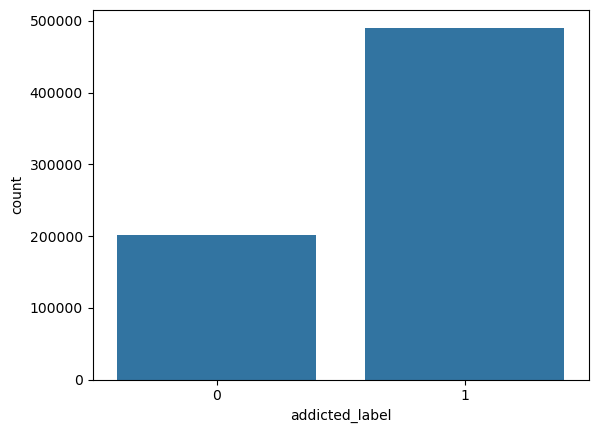

In [10]:
sns.countplot(x=train['addicted_label'])

<Axes: xlabel='stress_level', ylabel='count'>

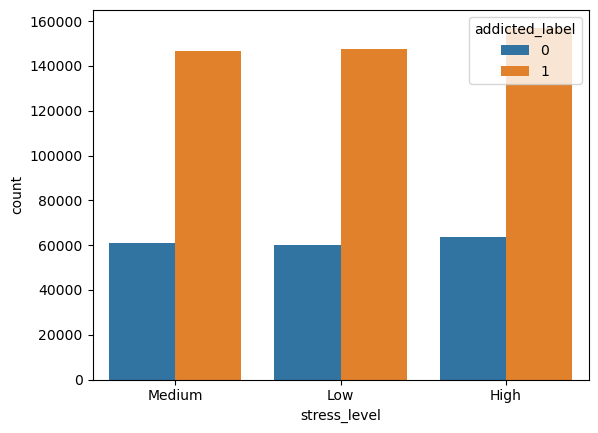

In [11]:
sns.countplot(x='stress_level', hue='addicted_label', data=train)

<Axes: xlabel='academic_work_impact', ylabel='count'>

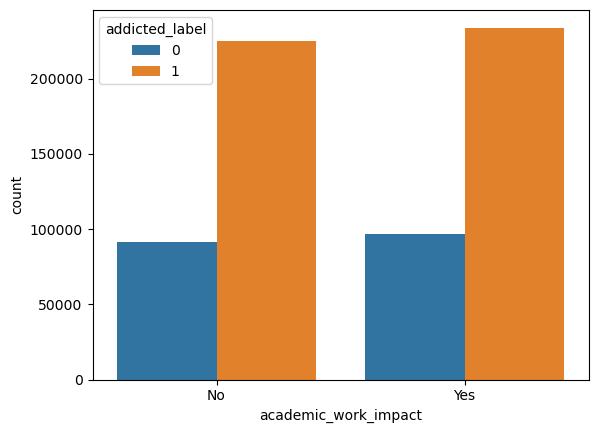

In [12]:
sns.countplot(x='academic_work_impact', hue='addicted_label', data=train)

<Axes: xlabel='gender', ylabel='count'>

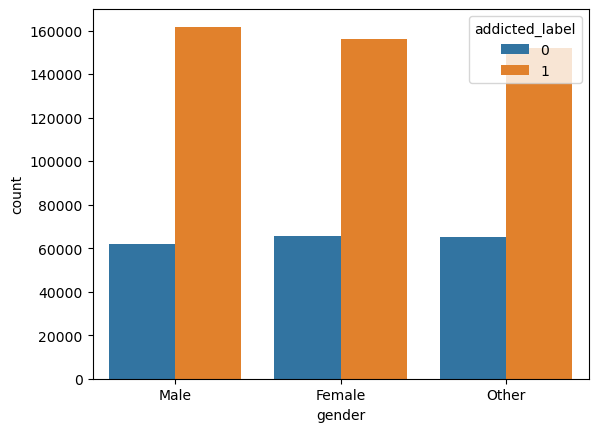

In [13]:
sns.countplot(x='gender', hue='addicted_label', data=train)

<Axes: xlabel='daily_screen_time_hours', ylabel='Count'>

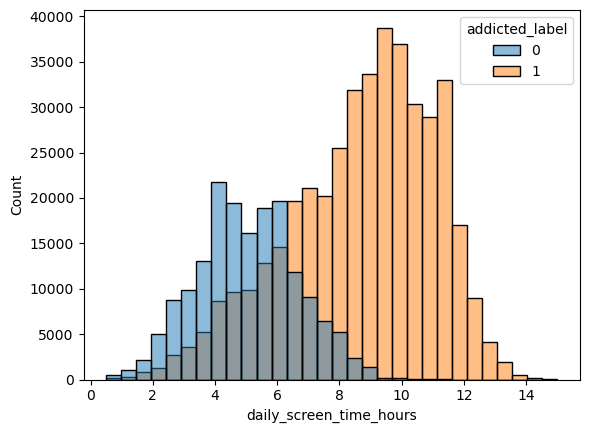

In [14]:
sns.histplot(x='daily_screen_time_hours', hue='addicted_label', data=train, bins=30)

<Axes: >

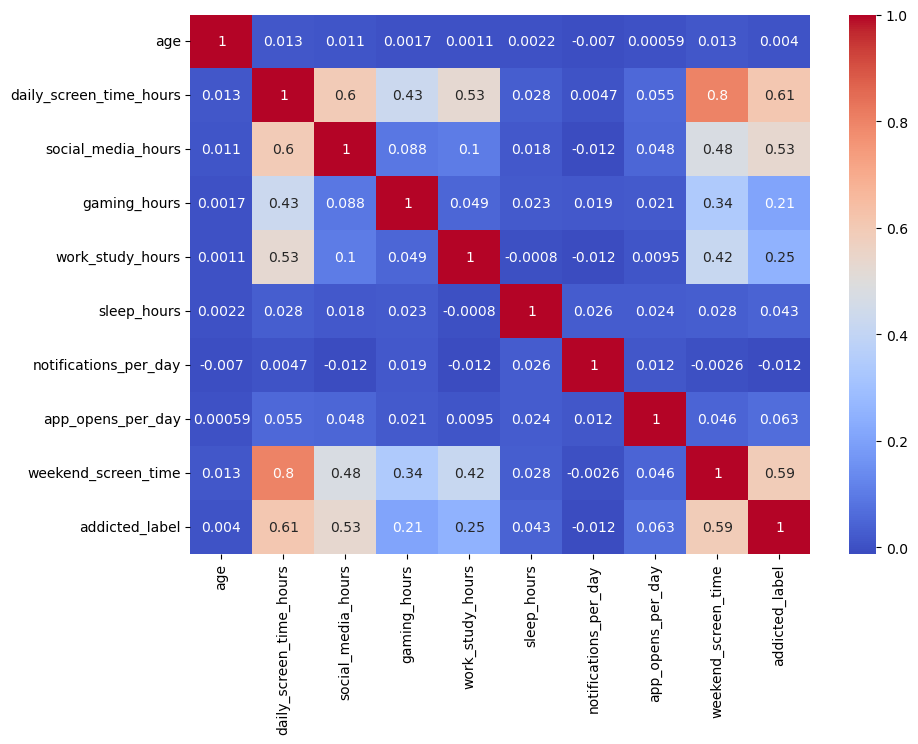

In [15]:
plt.figure(figsize=(10,7))
sns.heatmap(train.drop('id',axis=1).corr(numeric_only=True), annot=True, cmap='coolwarm')

In [16]:
n=len(train)  # train satır sayısı

In [17]:
df=pd.concat([train.drop('addicted_label',axis=1),test],ignore_index=True)

In [18]:
df=df.drop('id',axis=1)

In [19]:
kat=['gender','stress_level','academic_work_impact']
df[kat]=df[kat].fillna('Unknown')  # eksik kategorilere ayrı bir grup

In [20]:
df=pd.get_dummies(df,drop_first=True)

In [21]:
df.shape

(987671, 17)

In [22]:
x=df.iloc[:n]   # train kısmı
xt=df.iloc[n:]  # test kısmı

In [23]:
y=train['addicted_label']

In [24]:
from sklearn.model_selection import train_test_split

In [25]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.20,random_state=42)

In [26]:
from sklearn.metrics import accuracy_score, roc_auc_score

In [27]:
medyan=x_train.median()
xd_train=x_train.fillna(medyan)  # Logistic, Tree ve Forest için eksikleri medyanla doldur
xd_test=x_test.fillna(medyan)

In [28]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
xs_train=sc.fit_transform(xd_train)  # sadece Logistic için ölçekliyoruz
xs_test=sc.transform(xd_test)

In [29]:
from sklearn.linear_model import LogisticRegression
L=LogisticRegression(max_iter=1000)
L.fit(xs_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [30]:
p=L.predict_proba(xs_test)[:,1]
L_acc=accuracy_score(y_test,p>.5)
L_auc=roc_auc_score(y_test,p)
print(L_acc,L_auc)

0.8358982889046386 0.9115305068302042


In [31]:
from sklearn.tree import DecisionTreeClassifier
d=DecisionTreeClassifier(max_depth=8,random_state=42)
d.fit(xd_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,8
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [32]:
p=d.predict_proba(xd_test)[:,1]
d_acc=accuracy_score(y_test,p>.5)
d_auc=roc_auc_score(y_test,p)
print(d_acc,d_auc)

0.8559092815713728 0.9315132993433055


In [33]:
from sklearn.ensemble import RandomForestClassifier
r=RandomForestClassifier(n_estimators=100,max_depth=12,n_jobs=-1,random_state=42)
r.fit(xd_train,y_train)  # birkaç dakika sürebilir

,n_estimators,100
,criterion,'gini'
,max_depth,12
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [34]:
p=r.predict_proba(xd_test)[:,1]
r_acc=accuracy_score(y_test,p>.5)
r_auc=roc_auc_score(y_test,p)
print(r_acc,r_auc)

0.8642839579385857 0.9372411170138734


In [35]:
from sklearn.ensemble import HistGradientBoostingClassifier
g=HistGradientBoostingClassifier(max_iter=500,learning_rate=0.05,max_leaf_nodes=15,early_stopping=True,random_state=42)
g.fit(x_train,y_train)

,loss,'log_loss'
,learning_rate,0.05
,max_iter,500
,max_leaf_nodes,15
,max_depth,None
,min_samples_leaf,20
,l2_regularization,0.0
,max_features,1.0
,max_bins,255
,categorical_features,'from_dtype'
,monotonic_cst,None


In [36]:
p=g.predict_proba(x_test)[:,1]
g_acc=accuracy_score(y_test,p>.5)
g_auc=roc_auc_score(y_test,p)
print(g_acc,g_auc)

0.8911147431910554 0.9566689667256131


In [37]:
karsilastirma=pd.DataFrame({'model':['Logistic','Decision Tree','Random Forest','Gradient Boosting'],
                           'accuracy':[L_acc,d_acc,r_acc,g_acc],
                           'auc':[L_auc,d_auc,r_auc,g_auc]})
karsilastirma

,model,accuracy,auc
0,Logistic,0.835898,0.911531
1,Decision Tree,0.855909,0.931513
2,Random Forest,0.864284,0.937241
3,Gradient Boosting,0.891115,0.956669


In [38]:
model=HistGradientBoostingClassifier(max_iter=500,learning_rate=0.05,max_leaf_nodes=15,early_stopping=True,random_state=42)
model.fit(x,y)

,loss,'log_loss'
,learning_rate,0.05
,max_iter,500
,max_leaf_nodes,15
,max_depth,None
,min_samples_leaf,20
,l2_regularization,0.0
,max_features,1.0
,max_bins,255
,categorical_features,'from_dtype'
,monotonic_cst,None


In [39]:
tahmin=model.predict_proba(xt)[:,1]

In [40]:
sonuc=pd.DataFrame({'id':test['id'],'addicted_label':tahmin})

In [41]:
sonuc.to_csv('sonuc1.csv',index=False)

In [42]:
sonuc.head()

,id,addicted_label
0,691369,0.997616
1,691370,0.941685
2,691371,0.964633
3,691372,0.975499
4,691373,0.996061


In [43]:
sonuc.shape  # sample_submission ile aynı olmalı

(296302, 2)

In [44]:
import pickle

In [45]:
pickle.dump(model,open('telefon.pkl','wb'))
pickle.dump(list(x.columns),open('kolonlar.pkl','wb'))

In [46]:
kmodel=pickle.load(open('telefon.pkl','rb'))
kmodel.predict_proba(x.iloc[[0]])[0][1]  # ilk kişinin bağımlı olma olasılığı

np.float64(0.7911380806545386)

### Sonuç

Bu çalışmada yaşam tarzı bilgilerinden kişinin telefon bağımlısı olup olmadığını tahmin ettik. Verinin yaklaşık %71'i bağımlı sınıfındaydı. Sayısal sütunların çoğunda %5 ile %19 arasında eksik değer vardı. Kategorik sütunlardaki eksikleri `Unknown` grubuna aldık, sayısal eksikleri ise Logistic, Decision Tree ve Random Forest için medyanla doldurduk. Gradient Boosting eksik değerleri kendi işlediği için ona doldurulmamış veriyi verdik.

Dört modeli karşılaştırdık. Logistic Regression en zayıf sonucu verdi (AUC yaklaşık 0.91), Decision Tree ve Random Forest 0.93 civarında kaldı, Gradient Boosting ise yaklaşık **0.957 AUC** ve **%89 doğruluk** ile en iyisi oldu. Günlük ekran süresi, hafta sonu ekran süresi ve sosyal medya saati bağımlılıkla en güçlü ilişkisi olan değişkenlerdi.
